# QFF 2026 — PS-O3: 0/1 Knapsack

This notebook runs the reproducible p=1 QAOA benchmark for Processors B and D. Processor A has only five physical qubits and cannot execute the nine-qubit O3 circuit.

The notebook reports the exact classical reference, processor compilation metrics, synthetic-noise sampling results, and the O3 solution landscape. Results are simulator-based, not real-hardware measurements.

In [4]:
from src.problem import classical_bruteforce
from src.routing import optimize_qaoa_grid

classical_optimum, qubo_ground_states, qubo_ground_energy = classical_bruteforce()
print("Exact constrained classical optimum:", classical_optimum)
print("QUBO ground state(s):", qubo_ground_states)
print("QUBO ground energy:", qubo_ground_energy)
print("Selected p=1 QAOA parameters:", optimize_qaoa_grid())

Exact constrained classical optimum: {'bits': '11110', 'value': 26, 'weight': 14, 'feasible': True}
QUBO ground state(s): [[1, 1, 1, 1, 0, 1, 0, 0, 0]]
QUBO ground energy: -26.0
Selected p=1 QAOA parameters: {'expected_qubo_energy': 172.9960386954756, 'gamma': 0.30763272113248274, 'beta': 0.8103981633974484, 'p': 1, 'grid_gamma_steps': 13, 'grid_beta_steps': 13}


## Run the Processor B and Processor D benchmarks

The following cell runs the same logical nine-qubit O3 circuit on Processors B and D, simulates the configured synthetic noise, and writes tables and figures under `results/`. Processor A is excluded because it has only five physical qubits.

In [5]:
from run_experiment import main

main()

Classical constrained optimum: {'bits': '11110', 'value': 26, 'weight': 14, 'feasible': True}
QAOA parameters: {'expected_qubo_energy': 172.9960386954756, 'gamma': 0.30763272113248274, 'beta': 0.8103981633974484, 'p': 1, 'grid_gamma_steps': 13, 'grid_beta_steps': 13}

Circuit metrics:
   processor  logical_depth  transpiled_depth  logical_cx_equivalent  transpiled_cx_count  estimated_routing_swaps  transpiled_operation_count
Processor B             18               316                     72                  114                    14.00                         616
Processor D             18               227                     72                   98                     8.67                         493

Noisy sampled results:
   processor  shots  feasible_shot_rate  best_feasible_value_sampled  optimal_value_hit_rate most_common_bits  most_common_value  most_common_weight
Processor B   4096            0.917969                           26                0.015869            01101      

## Inspect generated results

The tables below compare circuit compilation and noisy sampling on Processors B and D. The landscape plot shows all 32 item subsets, separating feasible and infeasible solutions and marking the known optimum.

Processor circuit metrics


,processor,logical_depth,transpiled_depth,logical_cx_equivalent,transpiled_cx_count,estimated_routing_swaps,transpiled_operation_count
0,Processor B,18,316,72,114,14.00,616
1,Processor D,18,227,72,98,8.67,493


Noisy sampled results


,processor,shots,feasible_shot_rate,best_feasible_value_sampled,optimal_value_hit_rate,most_common_bits,most_common_value,most_common_weight
0,Processor B,4096,0.917969,26,0.015869,1101,19,13
1,Processor D,4096,0.918213,26,0.013916,1101,19,13


Processor comparison


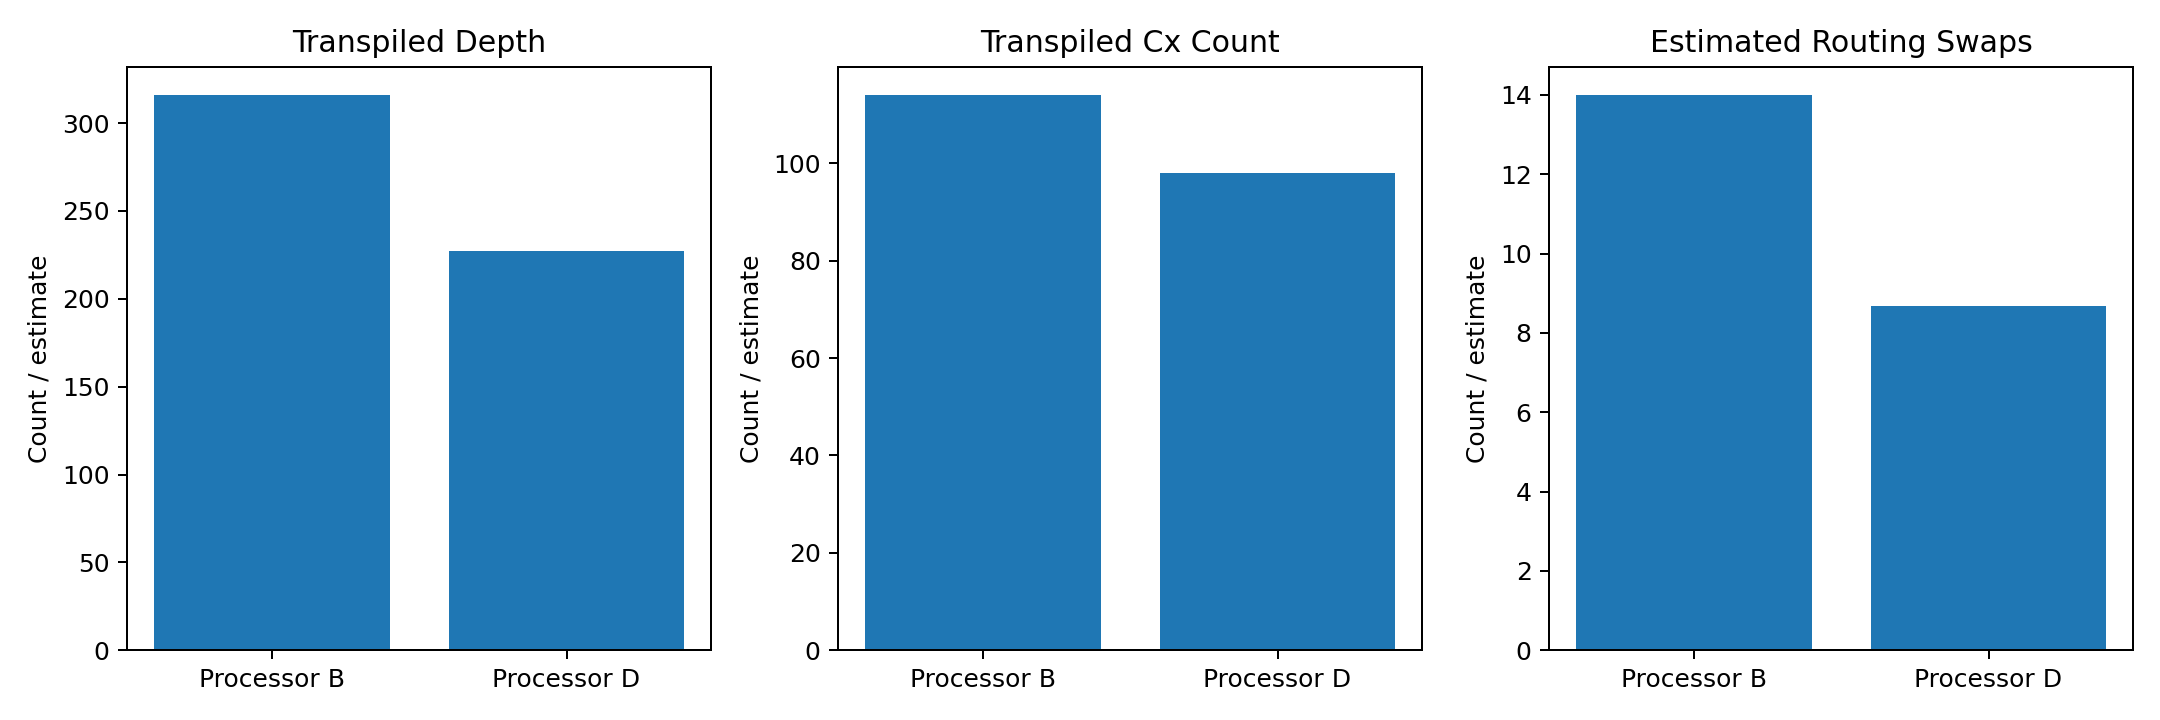

O3 solution landscape


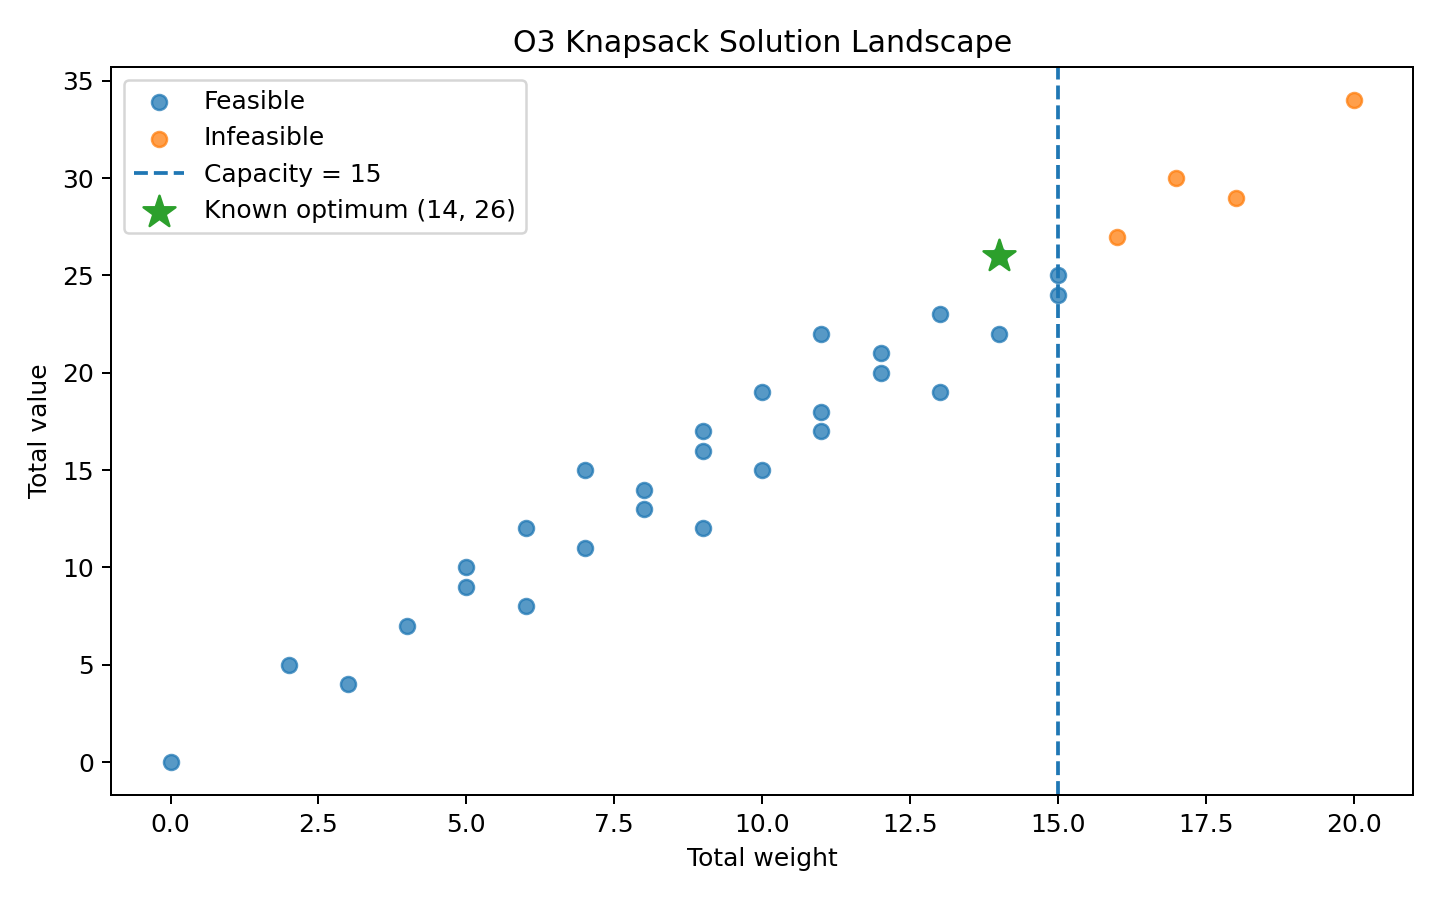

In [8]:
import pandas as pd
from IPython.display import Image, display

metrics = pd.read_csv("results/tables/processor_metrics.csv")
sampled = pd.read_csv("results/tables/sampled_results.csv")

print("Processor circuit metrics")
display(metrics)

print("Noisy sampled results")
display(sampled)

print("Processor comparison")
display(Image(filename="results/figures/processor_comparison.png"))

print("O3 solution landscape")
display(Image(filename="results/figures/o3_solution_landscape.png"))